<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/statistics/index.html">Statistics</a><span class="sep">·</span>Part 3 · Resampling</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">School maths. Python or R for the notebooks.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

An error measured on the data a model was fitted to is optimistic, because the fit has already bent towards that data's noise. Cross-validation scores every row with a model that never saw it: split the rows into $k$ folds, fit on $k-1$, score the one left out, rotate, and average. It estimates the expected error of your fitting procedure, not of the one model you finally fit. Three habits keep it honest. Use 5 or 10 folds: on synthetic data, one 75/25 holdout varied about twice as much as 5-fold. Treat any choice made from cross-validation scores as part of the fit: on pure noise, the best of 30 settings scored $58.7\%$ accuracy against a true $50\%$, and nested cross-validation gave $49.6\%$. And split by the unit you will predict for: plot-level folds put a random forest's error at $0.48$ when on new fields it was $1.75$. Afterwards you should be able to choose $k$, run nested and grouped cross-validation in scikit-learn, and say what the reported number means.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import (GridSearchCV, GroupKFold, KFold, LeaveOneOut,
                                     ShuffleSplit, StratifiedKFold, cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

# fallcolor is the site's colour module in tools/, not an installed package.
tools = next(p / "tools" for p in [Path.cwd(), *Path.cwd().parents] if (p / "tools" / "fallcolor.py").exists())
sys.path.insert(0, str(tools))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")

## Why training error flatters

A model scored on its own training rows is grading its own homework. [Least squares](../least-squares.qmd) makes the residuals on those rows as small as possible, so it fits some of their noise too, and the more flexible the model, the more it fits.

The fix is to score each row with a model fitted without it:

- **Holdout.** Fit on most rows, often three quarters, and score the rest.
- **$k$-fold.** Split the rows at random into $k$ folds; fit on $k-1$, score the one left out, and rotate until every fold has been scored.
- **Leave-one-out (LOO).** $k = n$: each fold is one row.

The $k$-fold estimate of mean squared error (MSE) is

$$\mathrm{CV}_k = \frac{1}{n} \sum_{i=1}^{n} \left( y_i - \hat{f}^{-\kappa(i)}(x_i) \right)^2$$

where $n$ is the number of rows, $(x_i, y_i)$ is row $i$, $\kappa(i)$ is the fold containing it, and $\hat{f}^{-\kappa}$ is the model fitted without fold $\kappa$. [Conformal prediction](../conformal-prediction/conformal_prediction.ipynb) builds prediction intervals from the residuals of these **out-of-fold predictions**. Stone's 1974 paper named cross-validation's two jobs in its title, choosing a predictor and assessing it[^1].

The example is **synthetic**: 50 rows with $x$ uniform on $[-1, 1]$ and $y = \sin(\pi x) + \varepsilon$, where $\varepsilon$ is independent normal noise with standard deviation $0.3$, so no model can beat an MSE of $0.09$ on new data. Polynomials of degree 1 to 10 are scored five ways, the last on 100,000 fresh rows that stand in for the truth.

In [2]:
SIGMA = 0.3  # noise standard deviation, so the best possible MSE is 0.09


def make_data(n, rng):
    x = rng.uniform(-1, 1, n)
    return x[:, None], np.sin(np.pi * x) + rng.normal(0, SIGMA, n)


def poly(degree):
    return make_pipeline(PolynomialFeatures(degree), LinearRegression())


def cv_mse(model, X, y, cv, groups=None):
    return -cross_val_score(model, X, y, cv=cv, groups=groups, scoring="neg_mean_squared_error").mean()


rng = np.random.default_rng(0)
X, y = make_data(50, rng)
X_new, y_new = make_data(100_000, rng)  # stands in for all future data

In [3]:
splitters = {
    "holdout": ShuffleSplit(1, test_size=0.25, random_state=0),
    "5-fold": KFold(5, shuffle=True, random_state=0),
    "LOO": LeaveOneOut(),
}
rows = []
for d in range(1, 11):
    fit = poly(d).fit(X, y)
    row = {"degree": d, "training": mean_squared_error(y, fit.predict(X))}
    row |= {name: cv_mse(poly(d), X, y, cv) for name, cv in splitters.items()}
    row["new data"] = mean_squared_error(y_new, fit.predict(X_new))
    rows.append(row)
sweep = pd.DataFrame(rows).set_index("degree")
sweep.loc[[1, 3, 5, 9, 10]].round(3)  # all ten degrees are in Figure 1

,training,holdout,5-fold,LOO,new data
degree,,,,,
1,0.319,0.445,0.339,0.347,0.293
3,0.094,0.133,0.108,0.110,0.100
5,0.089,0.168,0.112,0.114,0.093
9,0.080,9.979,0.137,0.132,0.104
10,0.078,4.786,0.274,0.208,0.107


Training error falls from $0.319$ at degree 1 to $0.078$ at degree 10, and from degree 5 it is below $0.09$, an error impossible on new data; adding terms to a least-squares fit can never raise it. Error on new data is lowest at degree 5 ($0.093$) and creeps up beyond it. Both cross-validation estimates pick degree 3 ($0.108$ by 5-fold, $0.110$ by LOO), whose error on new data is $0.100$. The single holdout reaches $9.979$ at degree 9, because one held-out row lay beyond the range of the training rows, where a degree-9 polynomial swings far from the data.

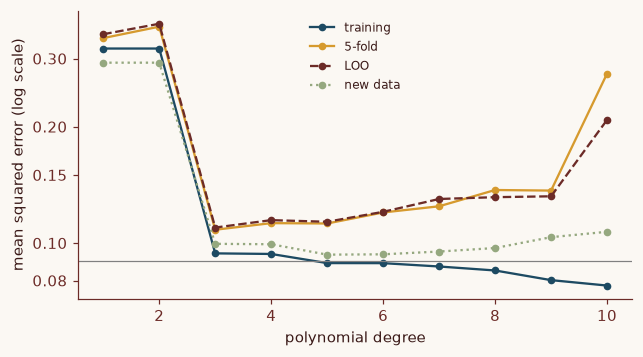

In [4]:
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for col, c, ls in [("training", C1, "-"), ("5-fold", C2, "-"), ("LOO", C3, "--"), ("new data", C4, ":")]:
    ax.plot(sweep.index, sweep[col], color=c, ls=ls, marker="o", ms=4, label=col)
ax.axhline(SIGMA**2, color="grey", lw=0.8)
ax.set(xlabel="polynomial degree", ylabel="mean squared error (log scale)", yscale="log")
ax.set_yticks([0.08, 0.1, 0.15, 0.2, 0.3], labels=["0.08", "0.10", "0.15", "0.20", "0.30"])
ax.minorticks_off()
ax.legend(frameon=False, fontsize=8)
plt.show()

**Figure 1 | Training error keeps falling; cross-validation does not.** Mean squared error of polynomial fits to one synthetic dataset of 50 rows, log scale. The grey line is the noise variance, $0.09$. The holdout runs off the scale and is omitted.

## How many folds

A cross-validation estimate depends on which rows land in which fold. Re-split the same 50 rows 200 times and score the cubic each time:

In [5]:
D = 3
one = pd.DataFrame({
    "holdout": [cv_mse(poly(D), X, y, ShuffleSplit(1, test_size=0.25, random_state=s)) for s in range(200)],
    "5-fold": [cv_mse(poly(D), X, y, KFold(5, shuffle=True, random_state=s)) for s in range(200)],
})
one.quantile([0.05, 0.5, 0.95]).round(3)  # across 200 random splits of the same 50 rows

,holdout,5-fold
0.05,0.060,0.103
0.50,0.107,0.110
0.95,0.167,0.123


Ninety per cent of holdout estimates fall between $0.060$ and $0.167$, almost a factor of three, depending only on which 13 rows were held out; 5-fold estimates fall between $0.103$ and $0.123$, around a true $0.100$. `RepeatedKFold` averages over several splits and shrinks this further. To see how each estimator tracks the truth, repeat on 300 independent datasets and compare with the error of each dataset's fitted cubic on the fresh rows:

In [6]:
estimators = splitters | {"2-fold": KFold(2, shuffle=True, random_state=0),
                         "10-fold": KFold(10, shuffle=True, random_state=0)}
sims = []
for s in range(300):  # 300 independent datasets of 50 rows
    Xs, ys = make_data(50, np.random.default_rng(1000 + s))
    fit = poly(D).fit(Xs, ys)
    row = {"new data": mean_squared_error(y_new, fit.predict(X_new)),
           "training": mean_squared_error(ys, fit.predict(Xs))}
    row |= {name: cv_mse(poly(D), Xs, ys, cv) for name, cv in estimators.items()}
    sims.append(row)
sims = pd.DataFrame(sims)
pd.DataFrame({"mean": sims.mean(), "sd": sims.std(), "corr. with new data": sims.corr()["new data"]}).round(3)

,mean,sd,corr. with new data
new data,0.104,0.007,1.000
training,0.087,0.017,0.025
holdout,0.104,0.042,0.056
5-fold,0.106,0.022,0.028
LOO,0.103,0.021,0.020
2-fold,0.114,0.032,-0.001
10-fold,0.104,0.021,0.020


**Bias and variance in $k$.** The error on new data averages $0.104$. Holdout, 5-fold, 10-fold and LOO all average within $0.002$ of it; 2-fold, whose models see only 25 rows, runs high at $0.114$. The spread falls from $0.042$ for one holdout to $0.022$ for 5-fold and $0.021$ for 10-fold and LOO. Here leave-one-out was no noisier than 10-fold; the best choice depends on the problem, and Arlot and Celisse survey the guidance[^2].

**What is being estimated.** Each estimate's correlation with the error of that dataset's own model is near zero, $-0.001$ to $0.056$. Cross-validation measures the fitting procedure, averaged over datasets like yours, not the one model you fitted:

$$\mathrm{Err}_\mathcal{T} = \mathbb{E}\left[ \left( Y - \hat{f}_\mathcal{T}(X) \right)^2 \,\middle|\, \mathcal{T} \right], \qquad \mathrm{Err} = \mathbb{E}_\mathcal{T}\left[ \mathrm{Err}_\mathcal{T} \right]$$

where $\mathcal{T}$ is the training set, $\hat{f}_\mathcal{T}$ the model fitted to it, and $(X, Y)$ a new row. The "new data" column is $\mathrm{Err}_\mathcal{T}$; cross-validation estimates $\mathrm{Err}$. For a model you retrain as data arrive, that is the right number: a fair estimate for the procedure, not a guarantee for this fit. Comparing models on the same folds remains sound, since procedures are what you are choosing between. Bates, Hastie and Tibshirani prove the result for least squares and show that the usual interval from the fold-to-fold spread is too narrow, so do not over-read small differences between models[^3].

## Choosing is part of fitting

Cross-validation is most often used to choose: a degree, a penalty, a set of features. Reporting the winner's score is a mistake, because the minimum of many noisy estimates is biased low, and more so the more settings are compared.

Varma and Simon showed how large this gets on "null" data, where labels have nothing to do with the features. The experiment below repeats the idea on 20 **synthetic** datasets of 60 rows and 500 noise features, with labels split 30/30 at random, so every classifier's true accuracy is exactly $50\%$. The model keeps the $m$ features most associated with the label (`SelectKBest`) and fits a penalised logistic regression; 6 values of $m$ and 5 penalties give 30 settings. Three estimates:

- **best of 30**: `GridSearchCV`'s 5-fold score of the winner, the number usually reported;
- **nested**: the whole search re-run inside each fold of an outer 5-fold split;
- **selected outside**: 20 features picked once on all rows, then 5-fold cross-validation.

In [7]:
pipe = make_pipeline(SelectKBest(f_classif), LogisticRegression(max_iter=2000))
grid = {"selectkbest__k": [5, 10, 20, 50, 100, 500], "logisticregression__C": [0.01, 0.1, 1, 10, 100]}
inner = StratifiedKFold(5, shuffle=True, random_state=0)
outer = StratifiedKFold(5, shuffle=True, random_state=1)

null = []
for s in range(20):  # 20 datasets: 60 rows, 500 noise features, labels unrelated to them
    Xc, yc = np.random.default_rng(s).normal(size=(60, 500)), np.repeat([0, 1], 30)
    search = GridSearchCV(pipe, grid, cv=inner, n_jobs=-1)
    best = search.fit(Xc, yc).best_score_  # CV accuracy of the best of 30 settings
    nested = cross_val_score(search, Xc, yc, cv=outer).mean()  # the whole search, re-run per outer fold
    picked = SelectKBest(f_classif, k=20).fit_transform(Xc, yc)  # the mistake: select on all rows first
    outside = cross_val_score(LogisticRegression(max_iter=2000), picked, yc, cv=inner).mean()
    null.append({"best of 30": best, "nested": nested, "selected outside": outside})
null = pd.DataFrame(null)
null.agg(["mean", "min", "max"]).round(3)  # every true accuracy is 0.5

,best of 30,nested,selected outside
mean,0.587,0.496,0.847
min,0.450,0.317,0.783
max,0.683,0.650,0.933


The reported best-of-30 score averages $58.7\%$. Nested cross-validation averages $49.6\%$, close to the true $50\%$, though single runs range from $31.7\%$ to $65.0\%$ with 60 rows. Varma and Simon found the same: a support vector machine tuned on their null data reported an error below $30\%$ on $38\%$ of datasets, against a true $50\%$, and nested cross-validation reduced the bias considerably[^4].

Selecting features outside the loop is far worse: $84.7\%$ from features carrying no information, because every test fold helped choose them. Ambroise and McLachlan traced published gene-expression classifiers with negligible error to this mistake, and showed the error was no longer zero once selection was redone inside the cross-validation[^5].

Both failures break the rule [Leakage](../leakage/leakage.ipynb) states: anything learned from data, whether feature selection, scaling, imputation or a tuned setting, must be learned again inside every training fold. Put the steps in a `Pipeline`, the choosing in `GridSearchCV`, and score the search with `cross_val_score`; ship the search fitted on all the data and report the nested score. Nesting multiplies the fits, here at least $30 \times 5 \times 5 = 750$ per dataset, so trim the grid, sample it with `RandomizedSearchCV`, or set `n_jobs=-1`.

## When rows come in groups

Random folds assume the rows are **exchangeable**: any row is as good a stand-in for a future row as any other. Rows from one field, grower or block share unrecorded conditions, and a model can learn them from a row's neighbours in the training folds, which it cannot do for a new field. In a production forecast the groups are often growers or blocks with many rows each.

The example is a **synthetic** nitrogen trial, 30 fields of 8 plots. Each plot gets its own nitrogen rate; soil pH and organic matter are measured once per field. Yield in t/ha is

$$y = 4 + 0.015\,N + 0.5\,(\mathrm{OM} - 3) + u + \varepsilon$$

where $N$ is nitrogen in kg/ha (0 to 200), $\mathrm{OM}$ is soil organic matter in % (mean 3, standard deviation 1), $u$ is everything unmeasured about the field (standard deviation 1 t/ha), and $\varepsilon$ is plot noise (standard deviation $0.4$ t/ha). pH has no effect. On a new field $u$ is unknown, so even a perfect model has MSE $1^2 + 0.4^2 = 1.16\ (\text{t/ha})^2$.

In [8]:
def trial(n_fields, plots, rng):
    """Synthetic field trial: plots nested in fields; soil is shared by a field's plots."""
    field = np.repeat(np.arange(n_fields), plots)
    ph = rng.normal(6.0, 0.5, n_fields)[field]
    om = rng.normal(3.0, 1.0, n_fields)[field]  # soil organic matter, %
    u = rng.normal(0, 1.0, n_fields)[field]  # everything else about the field, unmeasured
    n_rate = rng.uniform(0, 200, len(field))  # nitrogen applied, kg/ha, varies by plot
    yield_ = 4 + 0.015 * n_rate + 0.5 * (om - 3) + u + rng.normal(0, 0.4, len(field))
    return pd.DataFrame({"ph": ph, "om": om, "n_rate": n_rate}), yield_, field


rng = np.random.default_rng(0)
Xf, yf, field = trial(30, 8, rng)  # 240 plots
Xf_new, yf_new, _ = trial(2000, 8, rng)  # plots on fields the model has never seen

In [9]:
res = {}
for name, model in [("linear", LinearRegression()),
                    ("random forest", RandomForestRegressor(300, random_state=0, n_jobs=-1))]:
    res[name] = {
        "5-fold by plot": cv_mse(model, Xf, yf, KFold(5, shuffle=True, random_state=0)),
        "5-fold by field": cv_mse(model, Xf, yf, GroupKFold(5), groups=field),
        "new fields": mean_squared_error(yf_new, model.fit(Xf, yf).predict(Xf_new)),
    }
pd.DataFrame(res).T.round(2)  # MSE in (t/ha)^2

,5-fold by plot,5-fold by field,new fields
linear,1.36,1.52,1.23
random forest,0.48,1.87,1.75


For the random forest, plot-level folds report $0.48\ (\text{t/ha})^2$, below the $1.16$ no model can beat on a new field; on new fields it scores $1.75$. The forest used the soil columns, constant within a field, as a field identifier (pH included, although it has no effect) and learned each field's $u$ from its other plots. `GroupKFold`, which keeps a field's plots in one fold, reports $1.87$, slightly pessimistic since each fit sees 24 fields, not 30. The linear model cannot memorise fields: $1.36$ by plot, $1.52$ by field, $1.23$ on new fields. So the ranking flips: by plot the forest looks $1.36/0.48 = 2.8$ times better, on new fields it is worse, and plain $k$-fold would have chosen the wrong model.

Group by what the model will be used on: new plots in sampled fields, by plot; new fields or growers, by field or grower. Roberts and colleagues found that random cross-validation on structured ecological data seriously underestimates predictive error, but also that blocks can force a model to extrapolate and overstate it[^6]. With only a handful of groups, use `LeaveOneGroupOut`, one group per fold, and expect a noisy estimate. Nested and grouped together:

In [10]:
# Copy this: nested cross-validation, with each field's plots kept in one fold in both loops.
search = GridSearchCV(RandomForestRegressor(100, random_state=0, n_jobs=-1), {"min_samples_leaf": [1, 5, 20]},
                      cv=GroupKFold(5), scoring="neg_mean_squared_error")  # inner loop: chooses
scores = cross_val_score(search, Xf, yf, cv=GroupKFold(5), groups=field,  # outer loop: scores
                         params={"groups": field}, scoring="neg_mean_squared_error")
print(f"nested, grouped MSE: {-scores.mean():.2f} (t/ha)^2")
# Ungrouped: cross_val_score(GridSearchCV(pipe, grid, cv=inner), X, y, cv=outer)

nested, grouped MSE: 1.69 (t/ha)^2


It reports $1.69\ (\text{t/ha})^2$ for the forest with its leaf size tuned, close to the $1.75$ the untuned forest made on new fields (not a strict like-for-like check, since this forest is tuned). `groups` goes in twice: for the outer folds, and through `params` to the inner search.

Time is the strongest grouping. Do not use shuffled `KFold` on weekly rows: a test week's neighbours on both sides land in training, and the model learns from the future of the week it predicts. Use rolling-origin evaluation (`TimeSeriesSplit` in scikit-learn), as set out in [Backtesting properly](../backtesting/backtesting_properly.ipynb).

## Key takeaways

- Never report training error: a degree-10 polynomial scored $0.078$ on its own rows, below the noise floor of $0.09$.
- Cross-validation estimates the error of your fitting procedure on datasets like yours, the right number for a model you will retrain; the fold-to-fold spread understates its uncertainty.
- Use 5 or 10 folds, repeated on small data; one holdout split had about twice the spread of 5-fold.
- If scores chose anything, report a nested score: $49.6\%$ on null data, where the best of 30 reported $58.7\%$ and selecting features outside the folds $84.7\%$.
- Learn every step inside each fold, and group folds by the unit you will predict for. For weekly series, backtest with rolling origins.
## References

[^1]: Stone, M. Cross-validatory choice and assessment of statistical predictions. *J. R. Stat. Soc. B* **36**, 111–133 (1974). https://doi.org/10.1111/j.2517-6161.1974.tb00994.x
[^2]: Arlot, S. & Celisse, A. A survey of cross-validation procedures for model selection. *Stat. Surv.* **4**, 40–79 (2010). https://doi.org/10.1214/09-SS054
[^3]: Bates, S., Hastie, T. & Tibshirani, R. Cross-validation: what does it estimate and how well does it do it? *J. Am. Stat. Assoc.* **119**, 1434–1445 (2024). https://doi.org/10.1080/01621459.2023.2197686
[^4]: Varma, S. & Simon, R. Bias in error estimation when using cross-validation for model selection. *BMC Bioinformatics* **7**, 91 (2006). https://doi.org/10.1186/1471-2105-7-91
[^5]: Ambroise, C. & McLachlan, G. J. Selection bias in gene extraction on the basis of microarray gene-expression data. *Proc. Natl Acad. Sci. USA* **99**, 6562–6566 (2002). https://doi.org/10.1073/pnas.102102699
[^6]: Roberts, D. R. et al. Cross-validation strategies for data with temporal, spatial, hierarchical, or phylogenetic structure. *Ecography* **40**, 913–929 (2017). https://doi.org/10.1111/ecog.02881

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/t-test/the_t_test.html"><span>Previous</span>The t-test, and when not to use it</a><a class="mf-up" href="/series/statistics/index.html"><span>Series</span>Statistics</a><a class="mf-next" href="/blogs/least-squares.html"><span>Next</span>Least squares</a></div>
<!-- CURRICULUM_FOOTER_END -->